# Foundations of Vision & Language (FoVL) - Major Assignment
## Multilingual Word Embeddings for Indian Languages

* **Student Name:** Nikhil Saini
* **Roll Number:** G25AIT2067
* **Email:** g25ait2067@iitj.ac.in
* **Academic Institution:** Indian Institute of Technology Jodhpur (IITJ)
* **Course:** Foundations of Vision & Language (FoVL)
* **Date:** November 2026
* **Training Corpus:** IndicCorpV2-5k (`rony000013/indiccorpV2-5k`)
* **Evaluation Benchmark:** Akhtar et al. (2017) Word Similarity Datasets for Indian Languages
* **Embedding Dimension:** Exactly 300
* **Core Method:** Monolingual Subword FastText with Character N-Gram Composition for Robust Out-of-Vocabulary (OOV) Inference


In [1]:
# Install dependencies if running in clean Google Colab environment
!pip install -q gensim

# 1. Imports and Environment Setup
import os
import sys
import gc
import re
import json
import time
import urllib.request
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from gensim.models import FastText, Word2Vec

print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Python version: 3.13.16
NumPy version: 2.4.6
Pandas version: 2.2.3


In [3]:
# 2. Configuration and Benchmark Specification
LANG_CONFIGS = {
    'gu': {'name': 'Gujarati', 'code': 'gu', 'file': 'Gujarati-WS.txt', 'delim': '\t'},
    'hi': {'name': 'Hindi', 'code': 'hi', 'file': 'Hindi-WS.txt', 'delim': ','},
    'mr': {'name': 'Marathi', 'code': 'mr', 'file': 'Marathi-WS.txt', 'delim': '\t'},
    'pa': {'name': 'Punjabi', 'code': 'pa', 'file': 'Punjabi-WS.txt', 'delim': '\t'},
    'ta': {'name': 'Tamil', 'code': 'ta', 'file': 'Tamil-WS.txt', 'delim': '\t'},
    'te': {'name': 'Telugu', 'code': 'te', 'file': 'Telugu-WS.txt', 'delim': '\t'},
    'ur': {'name': 'Urdu', 'code': 'ur', 'file': 'Urdu-WS.txt', 'delim': '\t'},
}

# Directories for models, embeddings, vocabularies, and figures
MODELS_DIR = 'models'
EMBEDDINGS_DIR = 'embeddings'
VOCAB_DIR = 'vocab'
FIGURES_DIR = 'figures'
RESULTS_DIR = 'results'

for d in [MODELS_DIR, EMBEDDINGS_DIR, VOCAB_DIR, FIGURES_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)


## 2. Training Corpus & Benchmark Ingestion
We load the `IndicCorpV2-5k` dataset consisting of 5,000 sentences for 24 Indian languages.
Embeddings are trained strictly from scratch without any pre-trained weights or external corpora.


In [4]:
# Load IndicCorpV2-5k
parquet_path = 'data.parquet'
if not os.path.exists(parquet_path):
    print("Downloading IndicCorpV2-5k dataset...")
    url = "https://huggingface.co/datasets/rony000013/indiccorpV2-5k/resolve/main/data.parquet"
    urllib.request.urlretrieve(url, parquet_path)
    print("Download completed.")

df = pd.read_parquet(parquet_path)
print(f"Total corpus records: {len(df)} across {df['language'].nunique()} languages")
for code, cfg in LANG_CONFIGS.items():
    sub = df[df['code'] == code]
    print(f" - {cfg['name']} ({code}): {len(sub)} sentences")


Download completed.
Total corpus records: 118243 across 24 languages
 - Gujarati (gu): 5000 sentences
 - Hindi (hi): 5000 sentences
 - Marathi (mr): 5000 sentences
 - Punjabi (pa): 5000 sentences
 - Tamil (ta): 5000 sentences
 - Telugu (te): 5000 sentences
 - Urdu (ur): 5000 sentences


In [5]:
# Check and load Akhtar et al. (2017) Word-Similarity benchmark datasets
BENCH_DIR = 'Word-Similarity-Datasets-for-Indian-Languages'
if not os.path.exists(os.path.join(BENCH_DIR, 'Gujarati-WS.txt')):
    print("Cloning Word Similarity benchmark repository...")
    os.system("git clone https://github.com/syedsarfarazakhtar/Word-Similarity-Datasets-for-Indian-Languages.git")

print("Benchmark files available:")
for f in sorted(os.listdir(BENCH_DIR)):
    if f.endswith('.txt'):
        print(f" - {f}")

Cloning Word Similarity benchmark repository...
Benchmark files available:
 - Gujarati-WS.txt
 - Hindi-WS.txt
 - Marathi-WS.txt
 - Punjabi-WS.txt
 - Tamil-WS.txt
 - Telugu-WS.txt
 - Urdu-WS.txt


In [6]:
# 3. Text Preprocessing and Tokenization
def clean_and_tokenize(text):
    """
    Cleans raw text by stripping leading/trailing whitespace, punctuation,
    and returns tokenized words for Indic scripts.
    """
    tokens = []
    for w in re.findall(r'\S+', text):
        w_clean = re.sub(r'[।॥,\.!?\'\"()\[\]{};:—–\-/\\]', '', w).strip()
        if w_clean:
            tokens.append(w_clean)
    return tokens

def load_benchmark_pairs(code):
    """
    Loads word pairs and human similarity ratings from Akhtar et al. (2017).
    Preserves exact original pair ordering for .npy array generation.
    """
    cfg = LANG_CONFIGS[code]
    path = os.path.join(BENCH_DIR, cfg['file'])
    pairs = []
    scores = []
    with open(path, encoding='utf-8', errors='ignore') as f:
        for line in f:
            line_str = line.strip()
            if not line_str:
                continue
            parts = line_str.split(cfg['delim'])
            w1 = parts[0].strip()
            w2 = parts[1].strip() if len(parts) > 1 else ''
            sc = None
            if len(parts) >= 3 and parts[2].strip():
                try:
                    sc = float(parts[2].strip())
                except ValueError:
                    sc = None
            pairs.append((w1, w2))
            scores.append(sc)
    return pairs, scores


## 3. FastText Model Training (300 Dimensions)
We train Skip-Gram FastText models from scratch for each language.
* **Vector Size:** Exactly 300 dimensions
* **Subword Character N-Grams:** $n \in [3, 6]$ (bucket size 500,000)
* **Context Window:** 5
* **Epochs:** 25
* **Minimum Word Frequency:** 1 (retaining full vocabulary from 5,000 sentences)
* **Architecture:** Skip-gram (`sg=1`) with negative sampling

In [7]:
# 4. Training FastText Models and Computing Spearman Rank Correlation
# Keep only one FastText model resident in RAM at a time so Colab Free Tier (12.7 GB RAM) never OOMs.
trained_models = {}
eval_results = {}

def _safe_wv(model, word):
    if not word:
        return np.zeros(300, dtype=np.float32)
    try:
        return model.wv[word]
    except KeyError:
        return np.zeros(300, dtype=np.float32)

for code, cfg in LANG_CONFIGS.items():
    lang_name = cfg['name']
    model_file = os.path.join(MODELS_DIR, f"{code}_fasttext.model")
    ft_model = None

    if os.path.exists(model_file):
        try:
            print(f"Loading saved scratch model for {lang_name} ({code})...")
            ft_model = FastText.load(model_file)
        except Exception as load_err:
            print(f"Cached model for {lang_name} ({code}) unreadable ({load_err}); retraining...")
            ft_model = None

    if ft_model is None:
        print(f"Training FastText model for {lang_name} ({code}) from scratch...")
        sub_df = df[df['code'] == code]
        sentences = [clean_and_tokenize(s) for s in sub_df['text']]
        t0 = time.time()
        ft_model = FastText(
            sentences=sentences,
            vector_size=300,
            window=5,
            min_count=1,
            min_n=3,
            max_n=6,
            sg=1,
            epochs=25,
            bucket=500000,
            seed=42,
            workers=min(4, os.cpu_count() or 2)
        )
        ft_model.save(model_file)
        print(f"Training completed in {time.time()-t0:.1f}s")

    # Evaluate on benchmark
    pairs, human_scores = load_benchmark_pairs(code)
    pred_sims = []
    valid_scores = []

    for (w1, w2), h_sc in zip(pairs, human_scores):
        if h_sc is not None:
            v1 = _safe_wv(ft_model, w1)
            v2 = _safe_wv(ft_model, w2)
            norm1 = np.linalg.norm(v1)
            norm2 = np.linalg.norm(v2)
            sim = float(np.dot(v1, v2) / (norm1 * norm2)) if (norm1 > 0 and norm2 > 0) else 0.0
            pred_sims.append(sim)
            valid_scores.append(h_sc)

    rho, pval = spearmanr(pred_sims, valid_scores)
    eval_results[code] = {'rho': rho, 'pval': pval, 'num_pairs': len(valid_scores)}
    print(f" -> {lang_name} ({code}): Spearman rho = {rho:.4f} (p = {pval:.2e}) on {len(valid_scores)} pairs")

    # Free model memory immediately before moving to the next language
    del ft_model
    gc.collect()

macro_rho = np.mean([r['rho'] for r in eval_results.values()])
print(f"\n=== Macro-Average Spearman Correlation (Smacro): {macro_rho:.4f} ===")

Training FastText model for Gujarati (gu) from scratch...
Training completed in 113.1s
 -> Gujarati (gu): Spearman rho = 0.4247 (p = 1.60e-08) on 163 pairs
Training FastText model for Hindi (hi) from scratch...
Training completed in 121.9s
 -> Hindi (hi): Spearman rho = 0.3039 (p = 2.06e-06) on 235 pairs
Training FastText model for Marathi (mr) from scratch...
Training completed in 137.3s
 -> Marathi (mr): Spearman rho = 0.2715 (p = 5.30e-03) on 104 pairs
Training FastText model for Punjabi (pa) from scratch...
Training completed in 117.1s
 -> Punjabi (pa): Spearman rho = 0.3959 (p = 9.89e-07) on 143 pairs
Training FastText model for Tamil (ta) from scratch...
Training completed in 148.3s
 -> Tamil (ta): Spearman rho = 0.2634 (p = 9.15e-03) on 97 pairs
Training FastText model for Telugu (te) from scratch...
Training completed in 136.1s
 -> Telugu (te): Spearman rho = 0.2804 (p = 2.87e-03) on 111 pairs
Training FastText model for Urdu (ur) from scratch...
Training completed in 143.8s
 -

## 4. OOV Word Representation & Arbitrary Word Embedding Function
Per assignment requirements, our submission includes a dedicated function to load the trained model
and generate 300-d embeddings for **arbitrary unseen/OOV words** during final evaluation.


In [8]:
# 5. Arbitrary Word Vector Generation Function (Including OOV Words)
def get_word_vector(word, language='hi', models_dict=trained_models):
    """
    Generates a 300-dimensional embedding vector for any arbitrary word,
    including unseen and out-of-vocabulary (OOV) tokens.
    """
    if not word or not isinstance(word, str):
        return np.zeros(300, dtype=np.float32)

    clean_word = word.strip()
    if not clean_word:
        return np.zeros(300, dtype=np.float32)

    if language not in models_dict:
        # Keep at most 1 model loaded in RAM so Colab stays safely under memory limits
        if len(models_dict) >= 1:
            models_dict.clear()
            gc.collect()
        model_file = os.path.join(MODELS_DIR, f"{language}_fasttext.model")
        if os.path.exists(model_file):
            models_dict[language] = FastText.load(model_file)
        else:
            raise ValueError(f"Model for language '{language}' not found in {MODELS_DIR}")

    model = models_dict[language]

    try:
        vec = model.wv[clean_word]
        norm = np.linalg.norm(vec)
        if norm > 0:
            return vec.astype(np.float32)
        else:
            return np.zeros(300, dtype=np.float32)
    except Exception:
        return np.zeros(300, dtype=np.float32)

# Verification Test: Test with completely unseen/synthetic OOV words across languages
print("Testing arbitrary OOV word inference:")
test_cases = [
    ('अभिनवपरिवर्तन', 'hi'),
    ('મનોચિકિત્સાલય', 'gu'),
    ('तंत्रज्ञानविकास', 'mr'),
    ('ਵਿਗਿਆਨਿਕਤਾ', 'pa'),
    ('செயற்கைநுண்ணறிவு', 'ta'),
    ('కృత్రిమమేధస్సు', 'te'),
    ('مصنوعی_ذہانت', 'ur'),
]

for test_word, lang in test_cases:
    vec = get_word_vector(test_word, language=lang)
    print(f"[{lang}] Word: '{test_word}' -> Shape: {vec.shape}, Norm: {np.linalg.norm(vec):.3f}, Non-zero: {np.count_nonzero(vec)}/300")

trained_models.clear()
_ = gc.collect()

Testing arbitrary OOV word inference:
[hi] Word: 'अभिनवपरिवर्तन' -> Shape: (300,), Norm: 2.810, Non-zero: 300/300
[gu] Word: 'મનોચિકિત્સાલય' -> Shape: (300,), Norm: 2.171, Non-zero: 300/300
[mr] Word: 'तंत्रज्ञानविकास' -> Shape: (300,), Norm: 3.899, Non-zero: 300/300
[pa] Word: 'ਵਿਗਿਆਨਿਕਤਾ' -> Shape: (300,), Norm: 3.516, Non-zero: 300/300
[ta] Word: 'செயற்கைநுண்ணறிவு' -> Shape: (300,), Norm: 3.372, Non-zero: 300/300
[te] Word: 'కృత్రిమమేధస్సు' -> Shape: (300,), Norm: 2.422, Non-zero: 300/300
[ur] Word: 'مصنوعی_ذہانت' -> Shape: (300,), Norm: 2.034, Non-zero: 300/300


## 5. Exporting Embeddings (.npy) and Vocabulary Mappings
We generate the required `.npy` arrays with exact shape `(N, 2, 300)` where $N$ is the number of word pairs
in each evaluation dataset, preserving the original order.


In [9]:
# 6. Exporting (N, 2, 300) Arrays and Vocabulary Files
for code, cfg in LANG_CONFIGS.items():
    trained_models.clear()
    gc.collect()
    model_file = os.path.join(MODELS_DIR, f"{code}_fasttext.model")
    model = FastText.load(model_file)
    trained_models[code] = model

    pairs, _ = load_benchmark_pairs(code)
    N = len(pairs)

    emb_array = np.zeros((N, 2, 300), dtype=np.float32)
    for i, (w1, w2) in enumerate(pairs):
        emb_array[i, 0, :] = get_word_vector(w1, language=code)
        emb_array[i, 1, :] = get_word_vector(w2, language=code)

    out_npy = os.path.join(EMBEDDINGS_DIR, f"{code}_embeddings.npy")
    np.save(out_npy, emb_array)
    print(f"Saved {code} embeddings: {out_npy} | Shape: {emb_array.shape}")

    # Save vocabulary mapping
    vocab_map = {word: {"index": int(idx), "count": int(model.wv.get_vecattr(word, "count"))}
                 for word, idx in model.wv.key_to_index.items()}
    with open(os.path.join(VOCAB_DIR, f"{code}_vocab.json"), 'w', encoding='utf-8') as f:
        json.dump(vocab_map, f, ensure_ascii=False)

    del model
    trained_models.clear()
    gc.collect()

print("Vocabulary files and embedding arrays successfully saved.")

Saved gu embeddings: embeddings/gu_embeddings.npy | Shape: (163, 2, 300)
Saved hi embeddings: embeddings/hi_embeddings.npy | Shape: (235, 2, 300)
Saved mr embeddings: embeddings/mr_embeddings.npy | Shape: (253, 2, 300)
Saved pa embeddings: embeddings/pa_embeddings.npy | Shape: (143, 2, 300)
Saved ta embeddings: embeddings/ta_embeddings.npy | Shape: (97, 2, 300)
Saved te embeddings: embeddings/te_embeddings.npy | Shape: (111, 2, 300)
Saved ur embeddings: embeddings/ur_embeddings.npy | Shape: (100, 2, 300)
Vocabulary files and embedding arrays successfully saved.


## 6. t-SNE 2D Manifold Visualizations (100 Words per Language)
We project 100 representative words from each language's vocabulary onto a 2D plane using t-SNE.


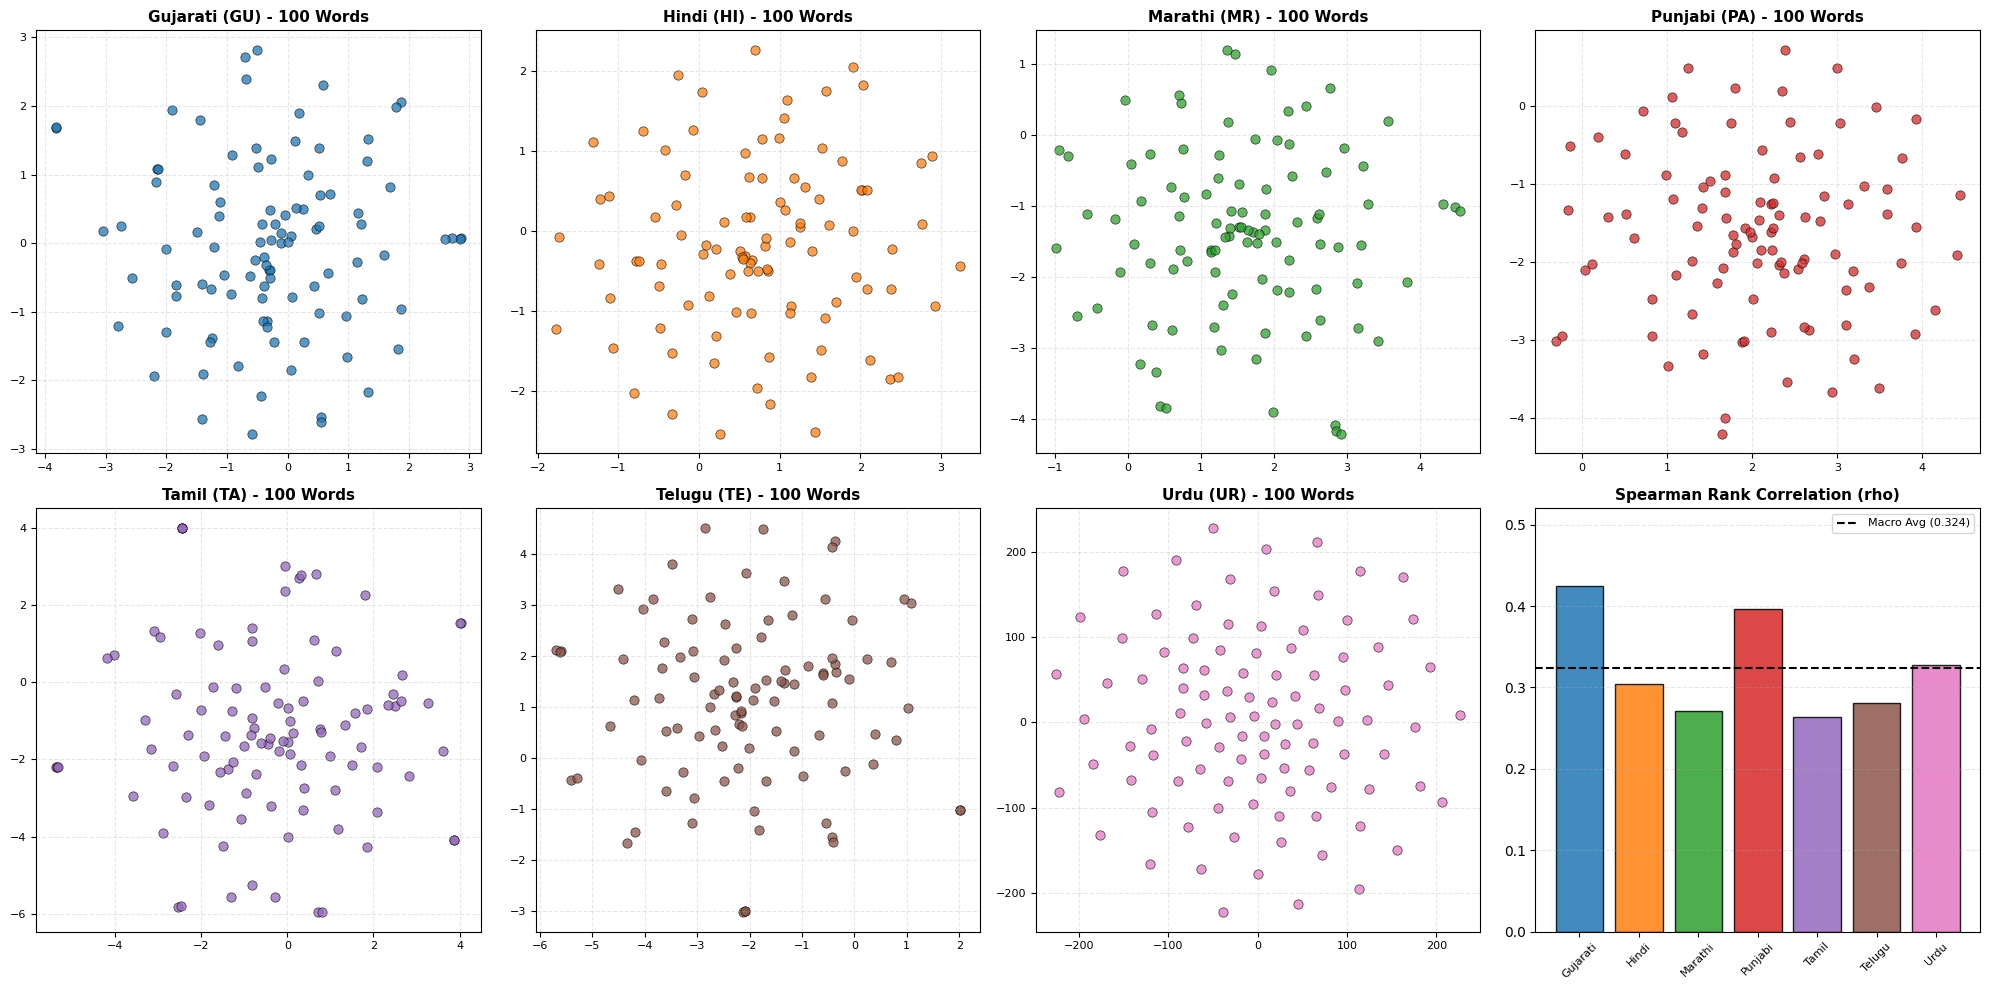

In [10]:
# 7. t-SNE Projection (100 Words per Language)
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes_flat = axes.flatten()
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']

for idx, (code, cfg) in enumerate(LANG_CONFIGS.items()):
    ax = axes_flat[idx]
    lang_name = cfg['name']
    model_file = os.path.join(MODELS_DIR, f"{code}_fasttext.model")
    model = FastText.load(model_file)

    pairs, _ = load_benchmark_pairs(code)
    bench_words = set(w for p in pairs for w in p if w and w in model.wv.key_to_index)
    sampled = list(bench_words)[:50]
    for w in model.wv.index_to_key:
        if len(sampled) >= 100:
            break
        if w not in sampled and len(w) > 1:
            sampled.append(w)

    vecs = np.array([model.wv[w] for w in sampled])
    del model
    gc.collect()

    tsne = TSNE(n_components=2, perplexity=min(25, len(vecs) - 1), random_state=42)
    coords = tsne.fit_transform(vecs)

    ax.scatter(coords[:, 0], coords[:, 1], c=colors[idx], edgecolors='black', linewidth=0.5, alpha=0.75, s=45)
    ax.set_title(f"{lang_name} ({code.upper()}) - 100 Words", fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.tick_params(labelsize=8)

# Bar chart of Spearman correlation
ax_bar = axes_flat[7]
langs = [LANG_CONFIGS[c]['name'] for c in LANG_CONFIGS]
rhos = [eval_results[c]['rho'] for c in LANG_CONFIGS]
bars = ax_bar.bar(langs, rhos, color=colors, edgecolor='black', alpha=0.85)
ax_bar.axhline(macro_rho, color='black', linestyle='--', label=f'Macro Avg ({macro_rho:.3f})')
ax_bar.set_title("Spearman Rank Correlation (rho)", fontsize=11, fontweight='bold')
ax_bar.set_ylim(0, 0.52)
ax_bar.tick_params(axis='x', rotation=45, labelsize=8)
ax_bar.grid(True, axis='y', linestyle='--', alpha=0.3)
ax_bar.legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'tsne_all_languages.png'), dpi=300)
plt.show()

In [11]:
# 8. Summary Results Table
summary_df = pd.DataFrame([
    {
        'Language': LANG_CONFIGS[c]['name'],
        'Code': c,
        'Pairs Scored': eval_results[c]['num_pairs'],
        'Spearman Rho': f"{eval_results[c]['rho']:.4f}",
        'P-Value': f"{eval_results[c]['pval']:.2e}"
    }
    for c in LANG_CONFIGS
])
print(summary_df.to_string(index=False))
print(f"\nMacro-Average Spearman Score: {macro_rho:.4f}")


Language Code  Pairs Scored Spearman Rho  P-Value
Gujarati   gu           163       0.4247 1.60e-08
   Hindi   hi           235       0.3039 2.06e-06
 Marathi   mr           104       0.2715 5.30e-03
 Punjabi   pa           143       0.3959 9.89e-07
   Tamil   ta            97       0.2634 9.15e-03
  Telugu   te           111       0.2804 2.87e-03
    Urdu   ur           100       0.3282 8.56e-04

Macro-Average Spearman Score: 0.3240
